# Unified CEBRA learns shared neural latents across recordings to discover single-neuron contributions to population codes

This is a demo notebook to run a Unified CEBRA model and work with the resulting feature attribution map (*[preprint coming]*, Célia Benquet, Hossein Mirzaei, Steffen Schneider, & Mackenzie Weygandt Mathis).

**Dataset:** Two-photon calcium recordings of mouse visual cortex from the Allen Brain Observatory (VISp, VISl, VISpm; excitatory, Vip, Pvalb and Sst neurons), in the processed form of [Deitch et al. 2021](https://github.com/zivlab/visual_drift), which builds on [de Vries et al. 2020](https://doi.org/10.1038/s41593-019-0550-9).

In this notebook, you will learn how to:
- Train a Unified CEBRA encoder with Jacobian regularization across 234 recordings sessions.
- Compute a neuron-level attribution map: how much each neuron moves the embedding along each movie feature, and in which direction (positive or negative).
- Read the map: find the top neurons for each feature, compare cell classes (excitatory, Vip, Pvalb and Sst), and inspect a single neuron's response next to its attribution.

In [1]:
#!pip install -q --pre 'cebra[demos]'

⏱️ Full execution takes about 2 minutes on one GPU. The embedding step runs on the GPU when it has about 12 GB free, and falls back to the CPU otherwise (about 3 minutes). Set `USE_CACHED_MODEL` to `True` to load the reference checkpoint (one model, run 0). Set it to `False` to train a model, which is slow (5,000 steps over 234 sessions) and is not run by default.

In [2]:
import os
USE_CACHED_MODEL = True
# Reference runs (unified, Allen visual cortex, 5000 steps; checkpoints only), shipped with the notebook in ./model/allen/
MODEL_DIR = "model/allen"
MODEL_PATH = os.path.join(MODEL_DIR, "261113-allen-unified-run0.pt")

### Set up imports and the device

In [ ]:
%matplotlib inline
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib import gridspec
import torch
from scipy.ndimage import gaussian_filter1d
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

import cebra
import cebra.models
import cebra.solver
import cebra.data
from cebra.attribution import average_feature_maps, feature_attribution_map, fit_feature_readout

sys.path.insert(0, os.getcwd())   # allen_demo_data.py sits next to this notebook
from allen_demo_data import (DEFAULT_CACHE, VALID_REPEAT, TRAIN_REPEATS, load_allen_demo, session_arrays,
                             session_tensor_datasets, wrapped_window_indices)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
                     "xtick.labelsize": 9, "ytick.labelsize": 9, "svg.fonttype": "none"})
SET2 = plt.get_cmap("Set2").colors
CLASS_COLORS = {"Py": "#959595", "Vip": "#B571F7", "Sst": "#20BCBC", "PV": "#8089F5"}
DISPLAY = {"Exc": "Py", "Vip": "Vip", "Sst": "Sst", "Pvalb": "PV"}   # cache names -> display names
CLASS_ORDER = ["Exc", "Vip", "Sst", "Pvalb"]                        # shown as Py, Vip, Sst, PV


def despine(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


### Load the Allen data

The data are the binary events of 2,924 neurons from 234 sessions, for 10 repeats of the 900-frame natural movie (repeats 0-8 train the model, repeat 9 is held out). They are downloaded once from [figshare](https://figshare.com/s/60adb075234c2cc51fa3?file=36869049) (from Schneider et al 2023).

`allen_demo_cache.npz`, also downloaded from [figshare](https://figshare.com/s/ae8099185f5e2f5e8185), gives the sessions, the neurons kept per session, their cell type and area, and the movie features.

In [4]:
# Download the processed Allen data (Deitch et al. 2021) from figshare, once. Only the two calcium folders are kept:
# DATA_DIR/allen/visual_drift/data/calcium_excitatory and .../calcium_inhibitory
import io, pathlib, shutil, tarfile, zipfile
import requests

DATA_DIR = pathlib.Path("data")
VISUAL_DRIFT_DIR = DATA_DIR / "allen" / "visual_drift" / "data"
KEEP = ("calcium_excitatory", "calcium_inhibitory")
FIGSHARE_PAGE = "https://figshare.com/s/60adb075234c2cc51fa3?file=36869049"
# figshare's file download host (https://docs.figshare.com/old_docs/api/articles/, "Downloading files")
FIGSHARE_URL = "https://ndownloader.figshare.com/files/36869049?private_link=60adb075234c2cc51fa3"


def wanted(name):
    """Archive member inside calcium_excitatory/ or calcium_inhibitory/, at any depth of the archive."""
    return any(part in KEEP for part in pathlib.PurePosixPath(name).parts)


if not all((VISUAL_DRIFT_DIR / k).is_dir() for k in KEEP):
    print("Downloading the processed Allen data from figshare...")
    response = requests.get(FIGSHARE_URL, timeout=600)
    content = io.BytesIO(response.content)
    tmp = DATA_DIR / "allen" / "_download"
    if response.status_code == 200 and zipfile.is_zipfile(content):
        with zipfile.ZipFile(content) as archive:
            archive.extractall(tmp, members=[m for m in archive.namelist() if wanted(m)])
    elif response.status_code == 200 and tarfile.is_tarfile(content):
        content.seek(0)
        with tarfile.open(fileobj=content) as archive:
            archive.extractall(tmp, members=[m for m in archive.getmembers() if wanted(m.name)], filter="data")
    folders = {k: next((p for p in tmp.rglob(k) if p.is_dir()), None) for k in KEEP} if tmp.exists() else {}
    if folders and all(folders.values()):
        VISUAL_DRIFT_DIR.mkdir(parents=True, exist_ok=True)
        for k, p in folders.items():
            shutil.move(str(p), str(VISUAL_DRIFT_DIR / k))
        shutil.rmtree(tmp)
    else:
        raise RuntimeError(f"Download failed (HTTP {response.status_code}, {len(response.content)} bytes). Download "
                           f"the file from {FIGSHARE_PAGE} in a browser and put its calcium_excitatory/ and "
                           f"calcium_inhibitory/ folders in {VISUAL_DRIFT_DIR}.")


In [5]:
# Download the metadata cache from the same Figshare article as the reference checkpoints.
import io, os, pathlib, shutil, zipfile
import requests

FIGSHARE_MODELS_PAGE = "https://figshare.com/s/ae8099185f5e2f5e8185"
FIGSHARE_MODELS_URL = "https://ndownloader.figshare.com/articles/29275358?private_link=ae8099185f5e2f5e8185"
CACHE_PATH = DEFAULT_CACHE

if not CACHE_PATH.exists():
    print("Downloading the Allen demo cache from figshare...")
    response = requests.get(FIGSHARE_MODELS_URL, timeout=600)
    response.raise_for_status()
    content = io.BytesIO(response.content)
    if not zipfile.is_zipfile(content):
        raise RuntimeError(f"Expected a zip archive from {FIGSHARE_MODELS_PAGE}.")
    with zipfile.ZipFile(content) as archive:
        members = [name for name in archive.namelist() if os.path.basename(name) == CACHE_PATH.name]
        if len(members) != 1:
            raise RuntimeError(f"Expected one {CACHE_PATH.name} in {FIGSHARE_MODELS_PAGE}, found {len(members)}.")
        CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
        with archive.open(members[0]) as source, open(CACHE_PATH, "wb") as destination:
            shutil.copyfileobj(source, destination)


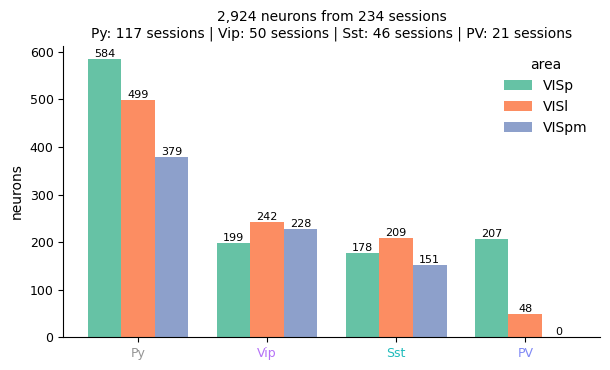

In [6]:
# events from the downloaded .mat files, metadata and movie features from allen_demo_cache.npz
demo = load_allen_demo(VISUAL_DRIFT_DIR, path=CACHE_PATH)
AREAS = ["VISp", "VISl", "VISpm"]
counts = np.array([[np.sum((demo.neuron_cell_class == c) & (demo.neuron_area == a)) for a in AREAS]
                   for c in CLASS_ORDER])
fig, ax = plt.subplots(figsize=(6.2, 3.8))
x, w = np.arange(len(CLASS_ORDER)), 0.26
for j, area in enumerate(AREAS):
    bars = ax.bar(x + (j - 1) * w, counts[:, j], w, color=SET2[j], label=area)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{int(b.get_height())}",
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [DISPLAY[c] for c in CLASS_ORDER])
for tick, c in zip(ax.get_xticklabels(), CLASS_ORDER):
    tick.set_color(CLASS_COLORS[DISPLAY[c]])
ax.set_ylabel("neurons")
ax.legend(frameon=False, title="area")
despine(ax)
ax.set_title(f"{demo.n_neurons:,} neurons from {demo.n_sessions} sessions\n" + " | ".join(
    f"{DISPLAY[c]}: {np.sum(demo.session_cell_class == c)} sessions" for c in CLASS_ORDER), fontsize=10)
plt.tight_layout()
plt.show()

A raster of one session per cell class (first repeat; rows are neurons):

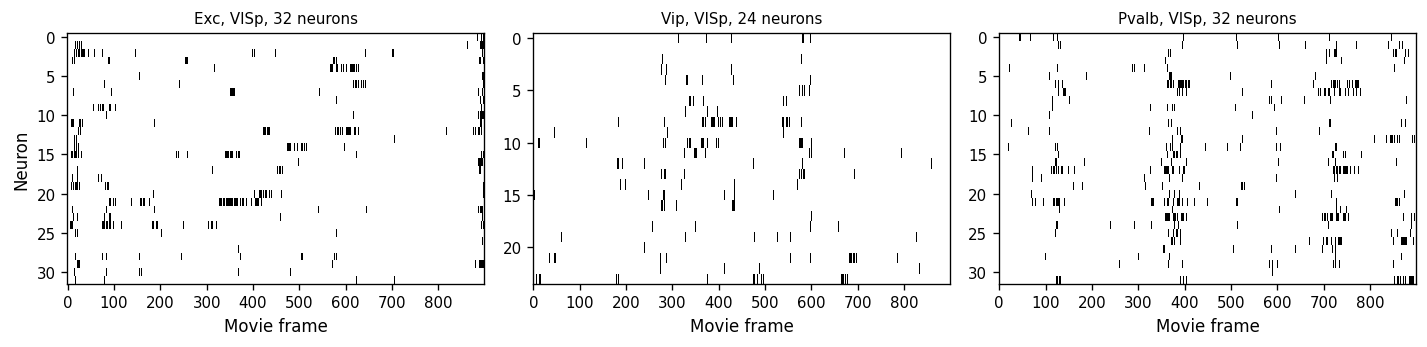

In [7]:
classes = ["Exc", "Vip", "Pvalb"]
example_sessions = [int(np.flatnonzero(demo.session_cell_class == c)[0]) for c in classes]

fig, axes = plt.subplots(1, 3, figsize=(12, 3), dpi=120)
for ax, s, c in zip(axes, example_sessions, classes):
    start, n = demo.session_neuron_start[s], demo.session_n_neurons[s]
    ax.imshow(demo.events[0, :, start:start + n].T, aspect="auto", cmap="Greys", interpolation="nearest")
    ax.set_title(f"{c}, {demo.session_area[s]}, {n} neurons", fontsize=9)
    ax.set_xlabel("Movie frame")
axes[0].set_ylabel("Neuron")
plt.tight_layout()
plt.show()

The six movie features (z-scored, one repeat). They are the readout target of the map.

In [8]:
feat_labels = [n.replace("_", " ") for n in demo.movie_feature_names]
feat_colors = plt.cm.Set2.colors[:len(feat_labels)]

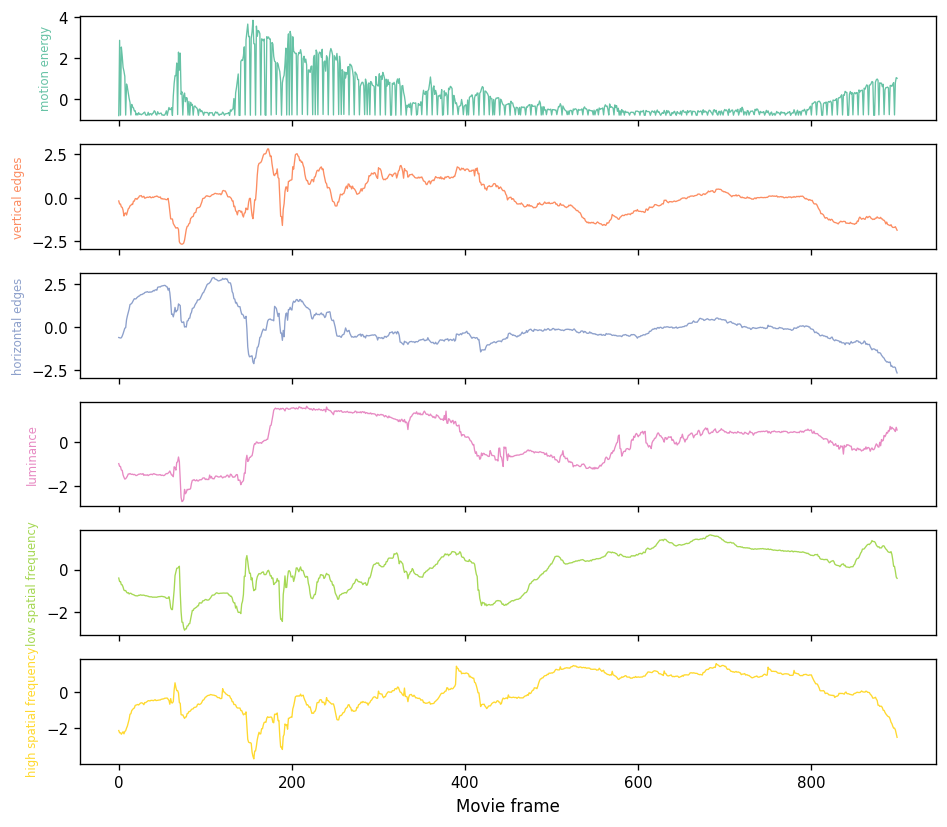

In [9]:
fig, axes = plt.subplots(6, 1, figsize=(8, 7), sharex=True, dpi=120)
for ax, name, y, color in zip(axes, demo.movie_feature_names, demo.movie_features.T, feat_colors):
    ax.plot(y, lw=0.8, color=color)
    ax.set_ylabel(name.replace("_", " "), fontsize=7, color=color)
axes[-1].set_xlabel("Movie frame")
plt.tight_layout()
plt.show()

### Load the model

The checkpoint is downloaded from (figshare)[https://figshare.com/s/ae8099185f5e2f5e8185] and is the `state_dict` of a unified xCEBRA solver (offset-10 encoder, 2,924 input neurons, 64 hidden units, 128 output dimensions).

In [10]:
# Download the reference checkpoints from figshare, once. The figshare item comes as one zip;
# only the files in MODEL_FILES are kept, in MODEL_DIR.
import io, zipfile
import requests

MODEL_FILES = [f"261113-allen-unified-run{run}.pt" for run in range(1)]   # range(3) for the averaging tip below

if USE_CACHED_MODEL and not all(os.path.exists(os.path.join(MODEL_DIR, f)) for f in MODEL_FILES):
    print("Downloading the reference checkpoints from figshare...")
    response = requests.get(FIGSHARE_MODELS_URL, timeout=600)
    content = io.BytesIO(response.content)
    if response.status_code == 200 and zipfile.is_zipfile(content):
        os.makedirs(MODEL_DIR, exist_ok=True)
        with zipfile.ZipFile(content) as archive:
            for member in archive.namelist():
                if os.path.basename(member) in MODEL_FILES:
                    with archive.open(member) as f, open(os.path.join(MODEL_DIR, os.path.basename(member)), "wb") as out:
                        out.write(f.read())
    missing = [f for f in MODEL_FILES if not os.path.exists(os.path.join(MODEL_DIR, f))]
    if missing:
        print(f"Download failed (HTTP {response.status_code}, {len(response.content)} bytes) or files missing: {missing}. "
              f"Download them from {FIGSHARE_MODELS_PAGE} in a browser and put them in {MODEL_DIR}/. "
              "Without them, set USE_CACHED_MODEL = False to train a model (slow).")


def load_solver(path):
    """Encoder and UnifiedSolverxCEBRA with the weights of one checkpoint."""
    model = cebra.models.init("offset10-model", num_neurons=demo.n_neurons, num_units=64, num_output=128)
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model.load_state_dict({k.removeprefix("module."): v for k, v in ckpt["model"].items()}, strict=True)
    solver = cebra.solver.UnifiedSolverxCEBRA(   # feature_attribution_map needs a solver with the Jacobian regularizer
        model=model,
        feature_ranges=[slice(0, 128)],
        regularizer=cebra.models.jacobian_regularizer.JacobianReg(),
        renormalize=True,
        criterion=cebra.models.FixedCosineInfoNCE(temperature=1.0),
        optimizer=torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=0.01),
        tqdm_on=False,
    )
    solver.n_features = int(ckpt["n_features"])
    solver.num_sessions = int(ckpt["num_sessions"])
    return solver


if USE_CACHED_MODEL:
    solver = load_solver(MODEL_PATH)
    print("loaded", MODEL_PATH, "| offset", solver.model.get_offset(), "| output dim", solver.model.num_output)

loaded model/allen/261113-allen-unified-run0.pt | offset Offset(left = 5, right = 5, length = 10) | output dim 128


### Train the model (optional)

This cell only runs when `USE_CACHED_MODEL` is `False` and uses the paper hyper-parameters. The solver is saved as a checkpoint only.

In [11]:
if not USE_CACHED_MODEL:
    from cebra.solver import MultiObjectiveConfig
    from cebra.solver.schedulers import LinearRampUp
    from cebra.data import UnifiedContrastiveMultiObjectiveLoader

    N_STEPS = 5000
    train_datasets = session_tensor_datasets(demo, TRAIN_REPEATS, device=device)
    dataset = cebra.data.UnifiedxCEBRADataset(*train_datasets)
    dataset.to(device)

    loader = UnifiedContrastiveMultiObjectiveLoader(dataset=dataset, num_steps=N_STEPS, batch_size=2048).to(device)
    config = MultiObjectiveConfig(loader)
    config.set_slice(0, 128)
    config.set_loss("FixedCosineInfoNCE", temperature=1.0)
    config.set_distribution("unified_time_delta", time_delta=10, label_name="continuous_index")
    config.push()
    config.finalize()
    for distribution in loader.distributions:
        if hasattr(distribution, "random_ties"):
            distribution.random_ties = True

    model = cebra.models.init(name="offset10-model", num_neurons=demo.n_neurons, num_units=64, num_output=128).to(device)
    dataset.configure_for(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=0.01)
    solver = cebra.solver.init(
        name="unified-xcebra",
        model=model,
        feature_ranges=config.feature_ranges,
        regularizer=cebra.models.jacobian_regularizer.JacobianReg(),
        renormalize=True,
        use_sam=False,
        criterion=config.criterion,
        optimizer=optimizer,
        tqdm_on=True,
    ).to(device)
    weight_scheduler = LinearRampUp(
        n_splits=1,
        step_to_switch_on_reg=N_STEPS // 4,
        step_to_switch_off_reg=N_STEPS // 2,
        start_weight=0.0,
        end_weight=0.06259457623404413,
    )
    solver.fit(loader=loader, scheduler_regularizer=weight_scheduler)
    solver.save(logdir="model", filename="allen-unified-run0.pt")

### Embeddings and a readout check

Embedding the 8,100 training frames takes about 3 minutes on the CPU, less on the GPU.

In [ ]:
def embed_session0(solver, repeats):
    """Embedding of session 0 for the given movie repeats.
    
    All sessions go in and auxiliary variable is the same across sessions.
    
    Tries the GPU first (the label copies need about 12 GB) and falls back to the CPU on out-of-memory.
    The seed fixes the tie draws, which are made on the CPU, so they are the same on every device."""
    arrays = session_arrays(demo, repeats)
    inputs = [torch.as_tensor(x, dtype=torch.float32) for x, _ in arrays]
    labels = [torch.as_tensor(y) for _, y in arrays]
    for dev in (["cuda", "cpu"] if device == "cuda" else ["cpu"]):
        try:
            solver.to(dev)
            emb = solver.transform(inputs, labels, session_id=0, batch_size=512, random_ties=True, seed=0).cpu().numpy()
            break
        except RuntimeError as err:   # torch.OutOfMemoryError, or cuBLAS/CUDA allocation failures
            if dev == "cpu" or not ("out of memory" in str(err).lower() or "CUDA" in str(err) or "CUBLAS" in str(err)):
                raise
            torch.cuda.empty_cache()
            print("GPU memory too small for the embedding, retrying on the CPU")
    solver.to(device)
    return emb


train_emb = embed_session0(solver, TRAIN_REPEATS)   # (8100, 128)
test_emb = embed_session0(solver, [VALID_REPEAT])   # (900, 128), held-out repeat

**First, global embedding decoding:** a ridge readout from the session-indexed embedding to the six features, fit on the training repeats and scored on the held-out repeat.

A high R2 here shows that the embedding carries the movie feature but doesn't provide a neuron-level granularity.

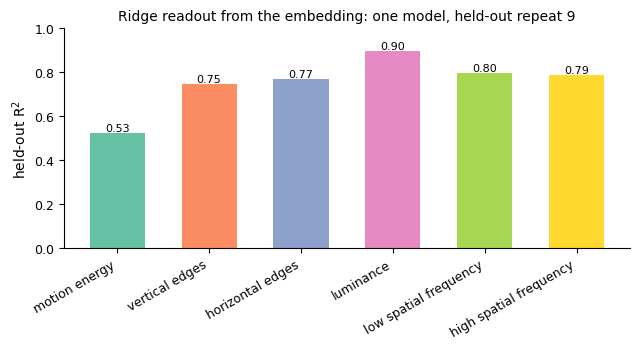

In [13]:
n_train = len(TRAIN_REPEATS)
readout = Ridge(alpha=n_train).fit(train_emb, np.tile(demo.movie_features, (n_train, 1)))
r2 = r2_score(demo.movie_features, readout.predict(test_emb), multioutput="raw_values")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(r2))
ax.bar(x, r2, color=SET2[:len(r2)], width=0.6)
for xi, v in zip(x, r2):
    ax.text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [n.replace("_", " ") for n in demo.movie_feature_names], rotation=30, ha="right")
ax.set_ylim(min(0.0, float(r2.min())), 1.0)
ax.set_ylabel("held-out R$^2$")
ax.set_title(f"Ridge readout from the embedding: one model, held-out repeat {VALID_REPEAT}", fontsize=10)
despine(ax)
plt.tight_layout()
plt.show()

### Attribution map

The map is `M = J̄ W` (neurons x features):

- `J̄`: the Jacobian of the encoder with respect to each neuron, averaged over the 900 frames of repeat 0.
- `W`: a ridge readout from the session-0 embedding to the six movie features. The embeddings of the 9 training repeats and of the held-out repeat are stacked, and the features are tiled once per repeat. The readout is fitted on the 9 training repeats (`train_fraction=0.9`).

`feature_attribution_map` computes the Jacobian and the product with `W` for one model. 
- `M[n, f] > 0`: raising the activity of neuron `n` moves the embedding towards larger values of feature `f`, inversly for `M[n, f] < 0`.
- The magnitude provides the strenght of the effect. 

In [14]:
# Inputs and labels of the training repeats, as lists over the sessions (the same as for the embeddings)
arrays = session_arrays(demo, TRAIN_REPEATS)
attr_inputs = [torch.as_tensor(x, dtype=torch.float32) for x, _ in arrays]
attr_labels = [torch.as_tensor(y) for _, y in arrays]
TRAIN_LENGTH = n_train * demo.n_frames                                     # 8,100 frames: the window wraps here
REF_INDICES = wrapped_window_indices(0, demo.n_frames, TRAIN_LENGTH, solver.model.get_offset())


def model_readout(train_emb, test_emb):
    """Readout W (D, 6) of one model: the training and held-out embeddings stacked, the features tiled once per
    repeat, and the first 90 % of the rows (the training repeats) fitted with penalty 9 (one per training repeat)."""
    stacked = np.concatenate([train_emb, test_emb])                         # 9 training repeats, then the held-out one
    features = np.tile(demo.movie_features, (n_train + 1, 1))
    return fit_feature_readout(stacked, features, alpha=float(n_train), train_fraction=0.9)


def feature_map(solver, train_emb, test_emb):
    """Signed map of one model, from its training and held-out embeddings."""
    return feature_attribution_map(
        solver, attr_inputs, model_readout(train_emb, test_emb), labels=attr_labels, session_id=0,
        indices=REF_INDICES, random_ties=True, seed=0,   # same alignment as embed_session0 (the model was trained with random ties)
        batch_size=128, latent_batch_size=64,
    )


readout = model_readout(train_emb, test_emb)                                # (128, 6)
M = feature_map(solver, train_emb, test_emb)                                # (N, 6)


**💡 Tip: more models give a more stable map.** 

One model run shows the real structure, but is only moderately reproducible: in the paper, the |M_f| of two models agree at about 0.6 (Spearman), and the paper averages 9 models for all results shown. To average, compute one map per model run and take `average_feature_maps`. The loop across 3 model runs is commented out below as an example.

In [15]:
# maps = [M]
# for run in range(1, 3):   # set MODEL_FILES to range(3) above to download runs 1 and 2
#     extra = load_solver(os.path.join(MODEL_DIR, f"261113-allen-unified-run{run}.pt"))
#     # each model gets its own readout, fitted on its own embedding
#     maps.append(feature_map(extra, embed_session0(extra, TRAIN_REPEATS), embed_session0(extra, [VALID_REPEAT])))
# M_avg = average_feature_maps(maps)

### Top neurons per feature

For each feature, the six neurons with the largest |M_f|: the feature's trace above each neuron's PSTH.

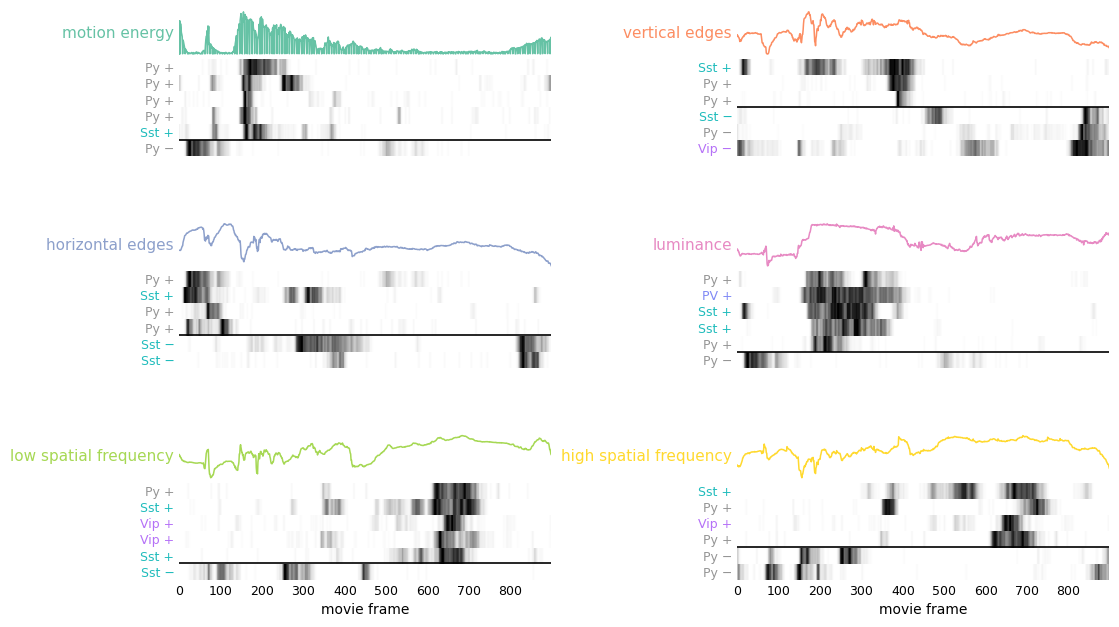

In [16]:
K_TOP = 6   # here, 0.2% of 2,924 neurons, can be adjusted as needed
FEAT_LABELS = [n.replace("_", " ") for n in demo.movie_feature_names]
fig = plt.figure(figsize=(12, 7.4))
outer = fig.add_gridspec(3, 2, hspace=0.45, wspace=0.5)
for fi in range(M.shape[1]):
    top = np.argsort(-np.abs(M[:, fi]))[:K_TOP]
    top = sorted(top, key=lambda n: (M[n, fi] < 0, -abs(M[n, fi])))   # enhancing first, then suppressing
    psth = np.stack([gaussian_filter1d(demo.events[:, :, n].mean(0).astype(float), 2) for n in top])
    psth = (psth - psth.min(1, keepdims=True)) / np.maximum(np.ptp(psth, axis=1, keepdims=True), 1e-9)
    inner = outer[fi // 2, fi % 2].subgridspec(2, 1, height_ratios=[1.1, 2.3], hspace=0.04)
    axt, axh = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
    axt.plot(demo.movie_features[:, fi], color=SET2[fi], lw=1.1)
    axt.set_xlim(0, demo.n_frames - 1)
    axt.axis("off")
    axt.text(-0.015, 0.5, FEAT_LABELS[fi], transform=axt.transAxes, ha="right", va="center",
             fontsize=11, color=SET2[fi])
    axh.imshow(psth, aspect="auto", cmap="Greys", vmin=0, vmax=1, interpolation="nearest",
               extent=(0, demo.n_frames - 1, K_TOP, 0))
    cls = [DISPLAY[demo.neuron_cell_class[n]] for n in top]
    axh.set_yticks(np.arange(K_TOP) + 0.5, [f"{c} {'+' if M[n, fi] > 0 else '−'}" for c, n in zip(cls, top)],
                   fontsize=9)
    for t, c in zip(axh.get_yticklabels(), cls):
        t.set_color(CLASS_COLORS[c])
    n_enh = int(sum(M[n, fi] > 0 for n in top))
    if 0 < n_enh < K_TOP:
        axh.axhline(n_enh, color="black", lw=1.2)
    axh.tick_params(length=0)
    for side in axh.spines.values():
        side.set_visible(False)
    if fi // 2 == 2:
        axh.set_xlabel("movie frame")
    else:
        axh.set_xticklabels([])
plt.show()

### Cell classes

Per cell class (rows) and movie feature (columns): signed mean $M_f$ over the neurons of the class, showing both magnitude and directionality. Values are centered around 0 (no preference), with positive and negative weights mapped symmetrically across a divergent colormap.

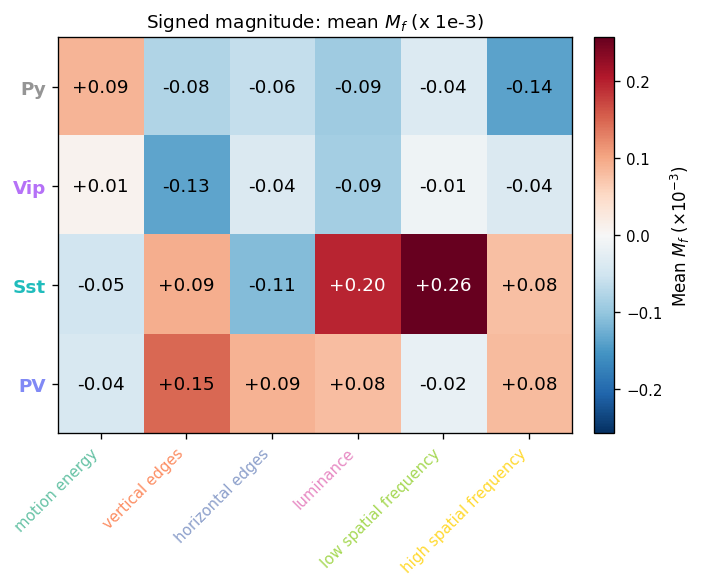

In [17]:
row_codes = ["Exc", "Vip", "Sst", "Pvalb"]
row_labels = ["Py", "Vip", "Sst", "PV"]
row_colors = ["#959595", "#B571F7", "#20BCBC", "#8089F5"]

# Signed mean across neurons per cell class
mean_signed = 1e3 * np.array([M[demo.neuron_cell_class == c].mean(axis=0) for c in row_codes])

# Symmetric limit centered at 0
vmax = np.abs(mean_signed).max()
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
cmap = plt.get_cmap("RdBu_r")

fig, ax = plt.subplots(figsize=(6, 5), dpi=120)

im = ax.imshow(mean_signed, cmap=cmap, norm=norm, aspect="auto")

ax.set_xticks(range(len(feat_labels)))
ax.set_xticklabels(feat_labels, rotation=45, ha="right", fontsize=9)
for tick, col in zip(ax.get_xticklabels(), feat_colors):
    tick.set_color(col)

ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=11, fontweight="bold")
for tick, col in zip(ax.get_yticklabels(), row_colors):
    tick.set_color(col)

for (r, c), v in np.ndenumerate(mean_signed):
    rgb = cmap(norm(v))[:3]
    lum = 0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2]
    ax.text(c, r, f"{v:+.2f}", ha="center", va="center", fontsize=11,
            color="black" if lum > 0.5 else "white")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r"Mean $M_f$ ($\times 10^{-3}$)", fontsize=10)

ax.set_title("Signed magnitude: mean $M_f$ (x 1e-3)", fontsize=11)
plt.tight_layout()
plt.show()

Magnitude is strongly tied to the firing rate of a neuron: neurons that fire more have larger |M|. Read the
directionality first, and treat magnitude differences between classes with more caution. For statistics, the paper uses a
session-level mixed model, which is not shown here.

### Investigate one neuron: its PSTH and its attribution per feature

The neuron with the largest |M| on any feature. 

*Left:* its peri-stimulus time histogram over the 9 training repeats
(fraction of repeats with an event per frame, smoothed over 15 frames), and the movie features for comparison. *Right:* its row of `M`.

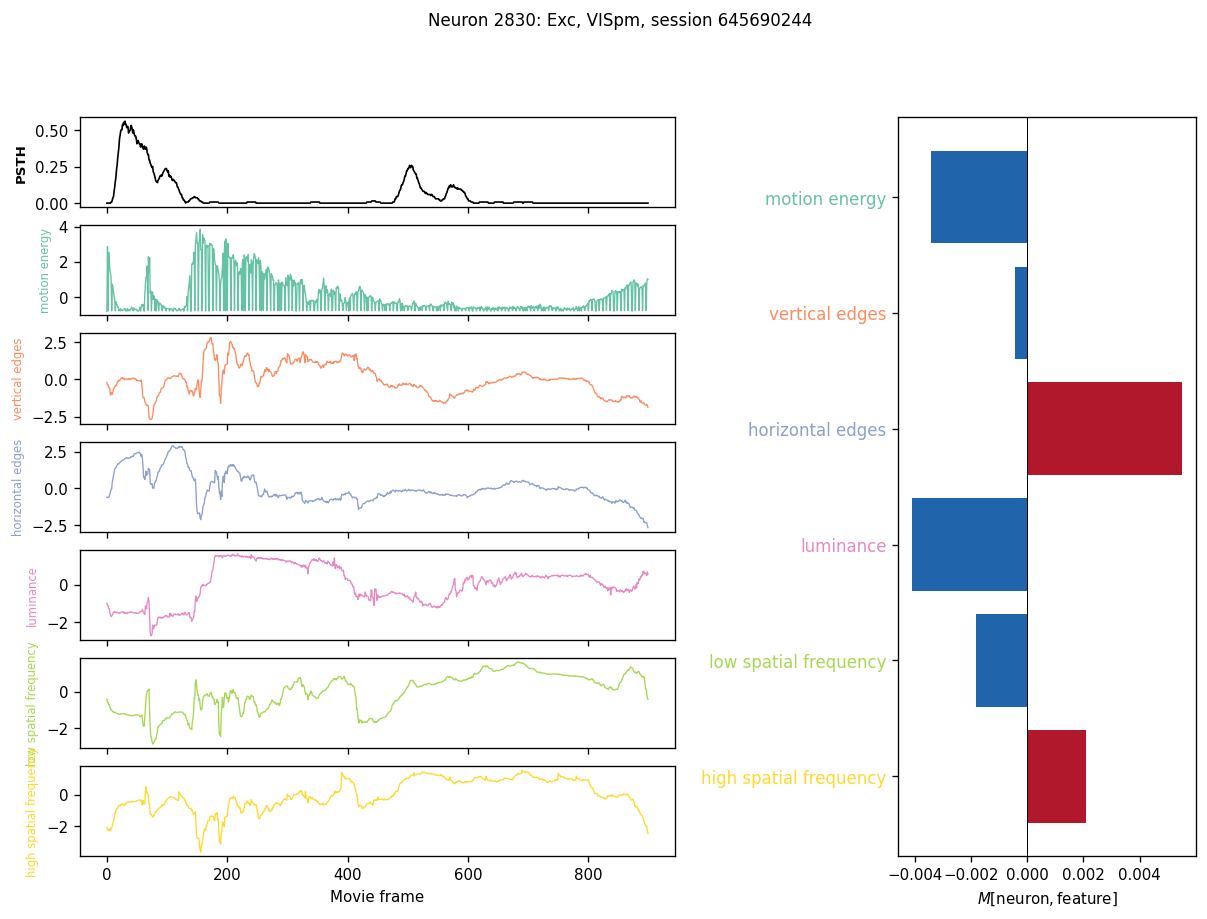

In [18]:
cmap = plt.get_cmap("RdBu_r")
c_pos, c_neg = cmap(0.9), cmap(0.1)

n_ex = int(np.argmax(np.abs(M).max(axis=1)))
psth = demo.events[np.arange(n_train), :, n_ex].mean(axis=0)
psth = np.convolve(psth, np.ones(15) / 15, mode="same")

n_feats = M.shape[1]
feat_names = [n.replace("_", " ") for n in demo.movie_feature_names]

fig = plt.figure(figsize=(12, 8), dpi=120)
gs = gridspec.GridSpec(
    nrows=n_feats + 1,
    ncols=2,
    width_ratios=[2, 1],
    hspace=0.2,
    wspace=0.5,
)

# 1. Top left: Neuron PSTH
ax_psth = fig.add_subplot(gs[0, 0])
ax_psth.plot(psth, lw=1, color="k")
ax_psth.set_ylabel("PSTH", fontsize=8, fontweight="bold")
ax_psth.tick_params(labelbottom=False)

# 2. Lower left: Stacked feature traces sharing x-axis with PSTH
feat_axes = []
for i in range(n_feats):
    share = ax_psth if i == 0 else feat_axes[0]
    ax = fig.add_subplot(gs[i + 1, 0], sharex=share)
    ax.plot(demo.movie_features[:, i], lw=0.8, color=feat_colors[i])
    ax.set_ylabel(feat_names[i], fontsize=7, color=feat_colors[i])
    if i < n_feats - 1:
        ax.tick_params(labelbottom=False)
    feat_axes.append(ax)

feat_axes[-1].set_xlabel("Movie frame", fontsize=9)

# 3. Right: Weights bar chart spanning all rows
ax_bar = fig.add_subplot(gs[:, 1])
bar_colors = [c_pos if v > 0 else c_neg for v in M[n_ex]]
ax_bar.barh(range(n_feats), M[n_ex], color=bar_colors)
ax_bar.set_yticks(range(n_feats))
ax_bar.set_yticklabels(feat_names, fontsize=10)
ax_bar.axvline(0, color="k", lw=0.6)
ax_bar.set_xlabel(r"$M[\mathrm{neuron}, \mathrm{feature}]$", fontsize=9)
ax_bar.invert_yaxis()  # Matches top-to-bottom order of traces

for tick, col in zip(ax_bar.get_yticklabels(), feat_colors):
    tick.set_color(col)

fig.suptitle(
    f"Neuron {n_ex}: {demo.neuron_cell_class[n_ex]}, {demo.neuron_area[n_ex]}, "
    f"session {demo.neuron_session_id[n_ex]}",
    fontsize=10,
    y=0.99,
)

plt.show()